# 05 · LightGBM quantile models (Stage 2)
**Goal:** beat the best baseline at every horizon (smart persistence at 1–2 h, climatology at 3–48 h) and give an uncertainty band.

**Setup**
- **Direct multi-horizon:** one model per (site, horizon h, quantile). Features come from `src/features.py` and use only data known at the origin t.
- **Quantiles:** P10, P50 and P90. P50 is the point forecast and P10–P90 is a nominal 80 % interval.
- **Tuning:** Optuna (15 trials) on 4 rolling-origin folds inside the training 80 %, with a 48 h gap between fold train and validation. The objective is daytime RMSE of P50.
- **Two weather modes**, as planned:
  - `lagged`: weather known at origin t only. This is the **realistic** model and the one compared with the baselines.
  - `forecast`: actual weather at t+h, standing in for a perfect weather forecast. This is an **upper bound**, not a deployable result.
- Same chronological split, daytime test rows and metrics as notebook 04.

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

from io_utils import FIG, ROOT, load_processed
from config import SITES
from features import build_features, chronological_split, leakage_check
from evaluation import all_baselines, evaluate, fit_clearsky_scale, interval_metrics, pinball, skill
from models import QUANTILES, fit_quantiles, predict_quantiles, tune

HORIZONS = [1, 2, 3, 4, 5, 6, 24, 36, 48]
MODES = ["lagged", "forecast"]
N_TRIALS = 15
data = {}
for s in ("primary", "site_a"):
    d = load_processed(s)
    d.attrs["tz"] = SITES[s]["tz"]
    data[s] = d

## 1. Leakage check
For every horizon, perturb the future and confirm that no past-based feature changes, and that no feature correlates perfectly with the target.

In [2]:
for s, d in data.items():
    for h in HORIZONS:
        leakage_check(d, h)
print("leakage check passed for all sites and horizons")

leakage check passed for all sites and horizons


## 2. Tune, train and predict
Hyperparameters are tuned per (site, horizon, mode) and shared by the three quantiles. Best params are saved to `reports/lgbm_params.json`.

In [3]:
preds, params = {}, {}
for s, d in data.items():
    for mode in MODES:
        for h in HORIZONS:
            train, test = chronological_split(build_features(d, h, weather_mode=mode))
            p = tune(train, n_trials=N_TRIALS)
            models = fit_quantiles(train, p)
            preds[(s, mode, h)] = predict_quantiles(models, pd.concat([train, test]))
            params[f"{s}|{mode}|{h}"] = p
            print(f"{s:8s} {mode:8s} h={h:2d}  cv RMSE {p['cv_rmse']*100:5.2f} %cap  trees {p['n_estimators']}")

with open(ROOT / "reports" / "lgbm_params.json", "w") as f:
    json.dump(params, f, indent=1)

primary  lagged   h= 1  cv RMSE  7.40 %cap  trees 814


primary  lagged   h= 2  cv RMSE  9.88 %cap  trees 208


primary  lagged   h= 3  cv RMSE 10.79 %cap  trees 354


primary  lagged   h= 4  cv RMSE 11.31 %cap  trees 181


primary  lagged   h= 5  cv RMSE 11.83 %cap  trees 370


primary  lagged   h= 6  cv RMSE 12.12 %cap  trees 193


... (26 outputs left out)

site_a   forecast h= 6  cv RMSE 13.17 %cap  trees 85


site_a   forecast h=24  cv RMSE 13.25 %cap  trees 55


site_a   forecast h=36  cv RMSE 13.31 %cap  trees 280


site_a   forecast h=48  cv RMSE 13.17 %cap  trees 280


## 3. Point accuracy against the baselines
All methods are scored on the same daytime test rows. Skill is measured against the **best baseline at that horizon**.

In [4]:
rows = []
for s, d in data.items():
    cut = d.index[int(len(d) * 0.8)]
    train = d[d.index < cut]
    mask = (d.index >= cut) & (d["is_day"] == 1)
    for h in HORIZONS:
        table = all_baselines(d, train, h, SITES[s]["tz"], fit_clearsky_scale(train))
        for mode in MODES:
            table[f"lgbm_{mode}"] = preds[(s, mode, h)]["p50"]
        for model, r in evaluate(d, table, mask).iterrows():
            rows.append({"site": s, "horizon_h": h, "model": model, **r.to_dict()})

results = pd.DataFrame(rows)
results["RMSE_%cap"] = results["RMSE"] * 100
results["MAE_%cap"] = results["MAE"] * 100
is_base = ~results["model"].str.startswith("lgbm")
best_base = results[is_base].loc[results[is_base].groupby(["site", "horizon_h"])["RMSE"].idxmin()]
ref = best_base.set_index(["site", "horizon_h"])
results["best_baseline"] = [ref.loc[(r.site, r.horizon_h), "model"] for r in results.itertuples()]
results["skill_vs_best_baseline"] = [skill(r.RMSE, ref.loc[(r.site, r.horizon_h), "RMSE"]) for r in results.itertuples()]

In [5]:
# RMSE (% of capacity), lower is better
results.pivot_table(index=["site", "model"], columns="horizon_h", values="RMSE_%cap").round(2)

horizon_h                     1      2      3      4      5      6      24     36     48
site    model                                                                           
primary climatology        15.38  15.38  15.38  15.38  15.38  15.38  15.38  15.36  15.38
        lgbm_forecast       1.69   1.73   1.77   1.73   1.80   1.92   1.82   1.80   1.86
        lgbm_lagged         8.04  10.08  11.24  12.02  12.66  13.15  13.95  14.91  15.03
        persistence        16.85  29.69  40.02  48.01  53.78  57.58  17.10  59.24  18.61
        seasonal_naive     17.10  17.10  17.10  17.10  17.10  17.10  17.10  18.37  18.61
        smart_persistence   8.46  11.53  13.66  15.42  16.68  17.72  17.11  20.53  18.64
site_a  climatology        17.13  17.13  17.13  17.13  17.13  17.13  17.14  16.91  16.92
        lgbm_forecast       9.41  10.77  11.20  11.17  11.16  11.47  11.40  11.25  11.19
        lgbm_lagged         9.56  12.08  13.01  13.68  13.78  14.16  17.02  16.74  16.52
        persistence        15.79  26.61  35.46  42.50  47.71  50.99  21.15  49.09  21.29
        seasonal_naive     21.14  21.14  21.14  21.14  21.14  21.14  21.15  21.29  21.29
        smart_persistence  11.04  15.62  18.84  21.64  23.96  25.62  21.17  28.78  21.35

In [6]:
# Skill of the LightGBM models against the best baseline at each horizon (> 0 = better)
results[~is_base].pivot_table(index=["site", "model"], columns="horizon_h", values="skill_vs_best_baseline").round(3)

horizon_h                 1      2      3      4      5      6      24     36     48
site    model                                                                       
primary lgbm_forecast  0.800  0.850  0.871  0.887  0.883  0.875  0.882  0.882  0.879
        lgbm_lagged    0.049  0.126  0.178  0.218  0.176  0.145  0.093  0.029  0.022
site_a  lgbm_forecast  0.148  0.311  0.346  0.348  0.348  0.330  0.335  0.335  0.339
        lgbm_lagged    0.134  0.227  0.241  0.201  0.196  0.174  0.007  0.010  0.024

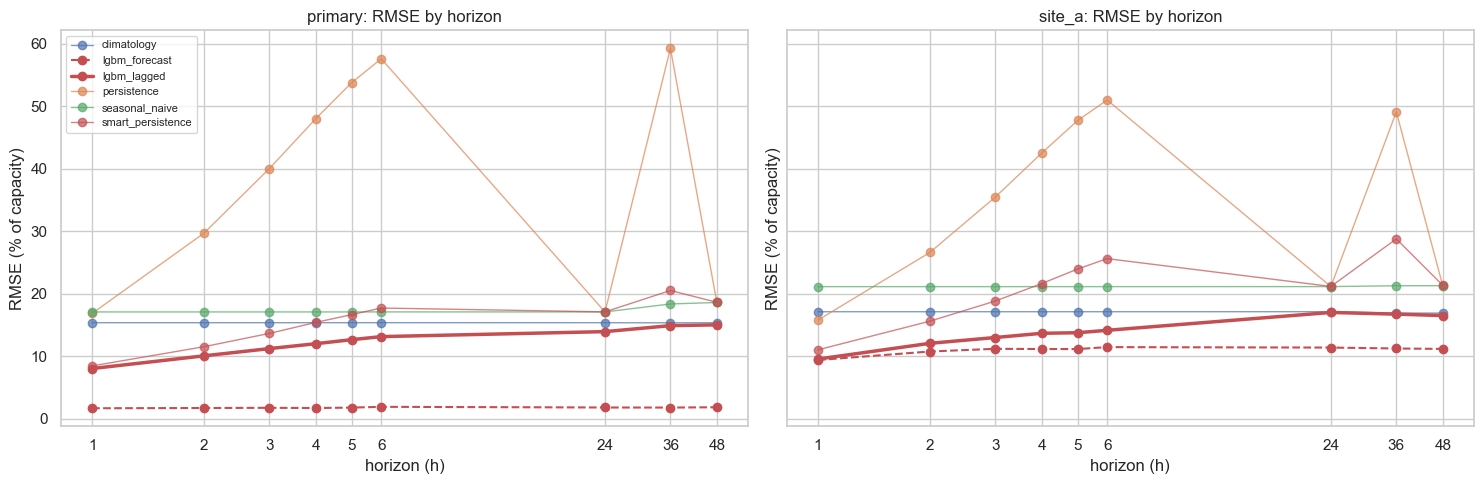

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
style = {"lgbm_lagged": dict(color="C3", lw=2.5), "lgbm_forecast": dict(color="C3", lw=1.5, ls="--")}
for i, s in enumerate(data):
    r = results[results["site"] == s]
    for m, g in r.groupby("model"):
        ax[i].plot(g["horizon_h"], g["RMSE_%cap"], marker="o", label=m, **style.get(m, dict(lw=1, alpha=.7)))
    ax[i].set_title(f"{s}: RMSE by horizon"); ax[i].set_xlabel("horizon (h)")
    ax[i].set_ylabel("RMSE (% of capacity)"); ax[i].set_xscale("log"); ax[i].set_xticks(HORIZONS, HORIZONS)
ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "13_lgbm_rmse_by_horizon.png", dpi=120); plt.show()

## 4. Uncertainty: P10–P90 interval
A well-calibrated 80 % interval should contain about 80 % of the actual values. Pinball loss scores each quantile (lower is better).

In [8]:
qrows = []
for (s, mode, h), P in preds.items():
    d = data[s]
    cut = d.index[int(len(d) * 0.8)]
    ok = (d.index >= cut) & (d["is_day"] == 1) & d["capacity_factor"].notna() & P.notna().all(axis=1)
    y, P = d.loc[ok, "capacity_factor"], P[ok]
    qrows.append({"site": s, "mode": mode, "horizon_h": h,
                  **interval_metrics(y, P["p10"], P["p90"]),
                  **{f"pinball_{k}": pinball(y, P[k], a) for k, a in QUANTILES.items()}})
qres = pd.DataFrame(qrows)
qres.pivot_table(index=["site", "mode"], columns="horizon_h", values="coverage").round(3)

horizon_h            1      2      3      4      5      6      24     36     48
site    mode                                                                   
primary forecast  0.648  0.630  0.626  0.647  0.642  0.634  0.609  0.562  0.665
        lagged    0.682  0.704  0.699  0.707  0.696  0.678  0.748  0.724  0.737
site_a  forecast  0.686  0.675  0.767  0.768  0.776  0.792  0.796  0.769  0.772
        lagged    0.704  0.711  0.784  0.777  0.786  0.827  0.846  0.816  0.844

In [9]:
# Mean interval width (% of capacity)
(qres.pivot_table(index=["site", "mode"], columns="horizon_h", values="width") * 100).round(1)

horizon_h           1     2     3     4     5     6     24    36    48
site    mode                                                          
primary forecast   3.8   3.7   3.5   3.8   3.7   4.1   3.4   3.3   4.1
        lagged    13.7  19.8  22.1  24.5  24.1  25.2  34.2  35.7  31.5
site_a  forecast  16.2  18.3  23.9  26.0  24.2  27.3  25.7  25.7  26.4
        lagged    16.0  21.2  26.5  27.6  28.6  32.9  41.8  38.6  41.4

## 5. Example forecasts on a test week (realistic `lagged` model)

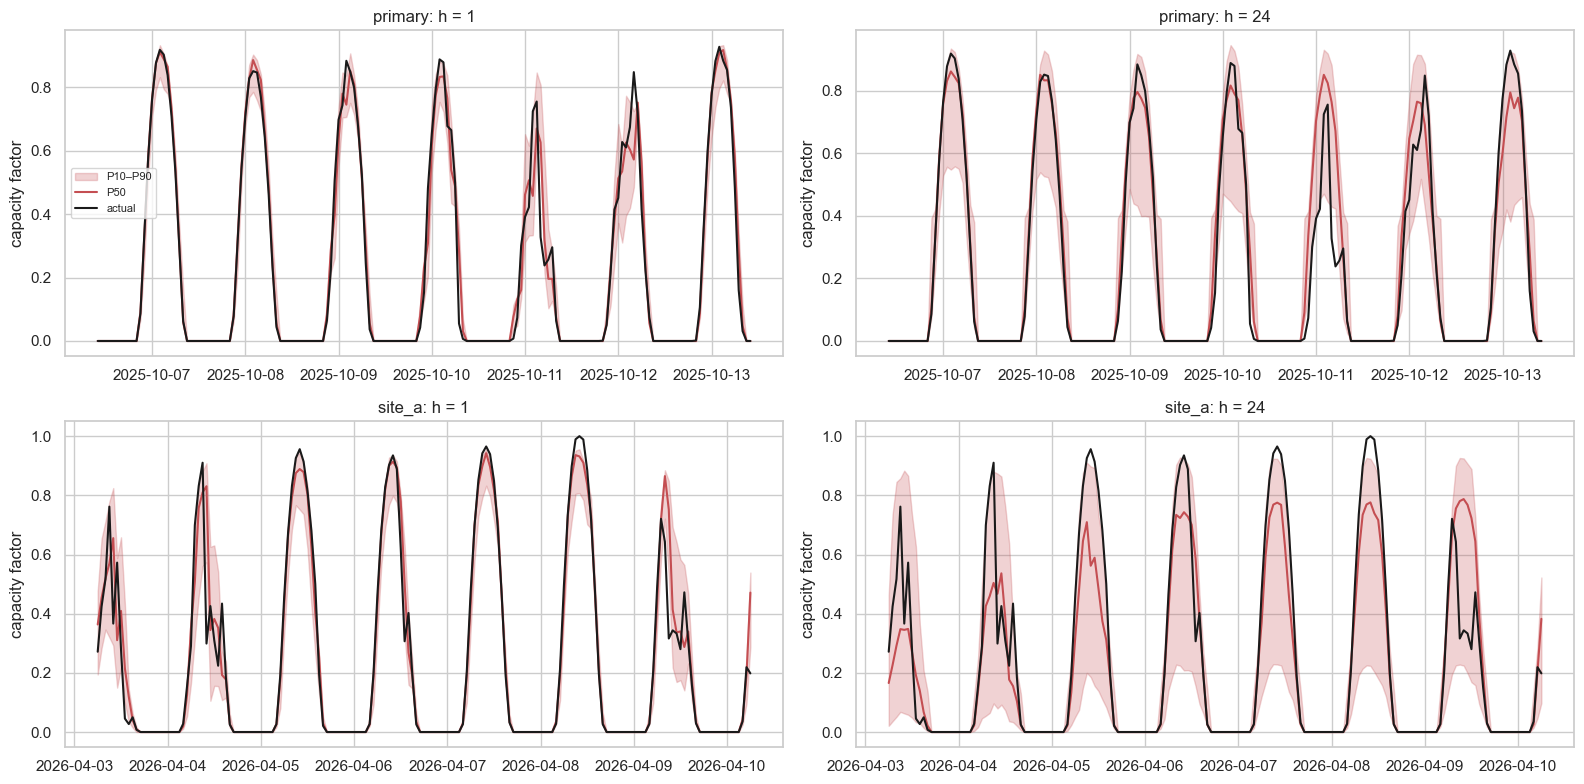

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(16, 8))
for i, s in enumerate(data):
    d = data[s]
    start = d.index[int(len(d) * 0.8)] + pd.Timedelta(days=20)
    w = slice(start, start + pd.Timedelta(days=7))
    for j, h in enumerate((1, 24)):
        P = preds[(s, "lagged", h)].loc[w]
        a = ax[i, j]
        a.fill_between(P.index, P["p10"], P["p90"], color="C3", alpha=.25, label="P10–P90")
        a.plot(P.index, P["p50"], color="C3", label="P50")
        a.plot(d.loc[w].index, d.loc[w, "capacity_factor"], color="k", lw=1.5, label="actual")
        a.set_title(f"{s}: h = {h}"); a.set_ylabel("capacity factor")
ax[0, 0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "14_lgbm_example_week.png", dpi=120); plt.show()

In [11]:
results.round(5).to_csv("../reports/lgbm_results.csv", index=False)
qres.round(5).to_csv("../reports/lgbm_quantile_results.csv", index=False)
print("saved reports/lgbm_results.csv and reports/lgbm_quantile_results.csv")

saved reports/lgbm_results.csv and reports/lgbm_quantile_results.csv


## Findings
1. **The realistic model (`lagged`) beats the best baseline at every horizon on both sites.** On the primary site the skill is +5 % at 1 h (8.0 vs 8.5 % RMSE), peaks at **+22 % at 4 h** (12.0 vs 15.4 %), and falls to +2 % at 48 h. On Site A it is +13 % at 1 h (9.6 vs 11.0 %) and **+24 % at 3 h**, but only about +1 % at 24–48 h.
2. **The gain is largest at 2–6 h.** That is where smart persistence has lost its value and climatology has not yet caught up. Recent output combined with geometry and calendar adds the most there. Beyond about 24 h, without weather forecasts, the model can do little better than climatology. This answers RQ1/RQ2.
3. **The weather inputs are what matters for day-ahead forecasts.** With actual target-hour weather (`forecast` mode, upper bound) the RMSE drops to **≈ 1.8 %** at every horizon on the primary site, and to about 11 % on Site A, where cloudy weather is noisier. The gap between the two modes is the value of a good weather forecast. In deployment, the `forecast` mode would be fed by an NWP forecast rather than measurements.
4. **The intervals are too narrow.** The nominal 80 % P10–P90 interval covers only 68–75 % on the primary site and 70–85 % on Site A for the `lagged` model. In `forecast` mode it covers 56–66 % on the primary site. Intervals widen with horizon as they should (14 → 34 % of capacity at the primary site), but conformal calibration would be needed before the intervals are used for decisions.
5. **Site A remains the harder site** at every horizon, which is consistent with the EDA and the baselines.